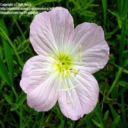

In [2]:
import torchvision
import torch
from PIL import Image

# Define image size 
size = (128, 128)

# Preprocess images: resize and convert to Tensor
transform = torchvision.transforms.Compose([
    torchvision.transforms.Resize(size),  # Resize to 128x128
    torchvision.transforms.ToTensor(),    # Convert to Tensor and scale pixels to [0, 1]
])

# Load training and testing datasets
train_dataset = list(torchvision.datasets.Flowers102(
    "../Introduction/flowers", "train", transform=transform, download=False
))

test_dataset = list(torchvision.datasets.Flowers102(
    "../Introduction/flowers", "test", transform=transform, download=False
))


# Convert a PyTorch Tensor into a PIL Image for visualization
def visualize_image(img: torch.Tensor) -> Image.Image:
    img = img.permute(1, 2, 0)  # Convert CHW to HWC
    img = (img * 255).to(torch.uint8)  # Scale pixels to [0, 255]
    return Image.fromarray(img.numpy())  # Convert to PIL Image


# Visualize the first training image
visualize_image(train_dataset[1][0])  # [0] selects the image, [1] is the label

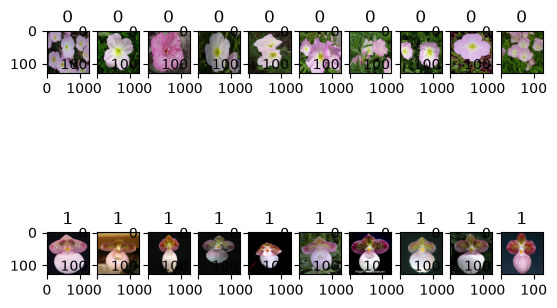

In [4]:
import matplotlib.pyplot as plt
f, ax = plt.subplots(2,10)
for i, (img, label) in enumerate(list(train_dataset)[:20]):
    ax[i//10, i%10].imshow(visualize_image(img))
    ax[i//10, i%10].set_title(label)

class_01 = list(train_dataset)[:20]

In [5]:
# 1. Pre-processing data
train_images = torch.stack([im for im, _ in train_dataset], dim = 0)
train_images.shape
train_label = torch.tensor([label for _,label in train_dataset])
train_label.dtype

torch.int64

In [ ]:
train_images, train_label = train_images.cuda(), train_label.cuda()

In [9]:
# Model

model = torch.nn.Linear(128*128*3,102)
model.cuda()
loss = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr = 0.01)
# Single sample SGB
for epoch in range(10):
    avg_loss = []
    for i in range(0, len(train_images)):
        # Compute model predictions
        pred_label = model(train_images[i].view(-1,128 * 128 *3))
        optimizer.zero_grad()
        # Compute loss
        loss_val = loss(pred_label, train_label[None, i])
        # Compute gradients
        loss_val.backward()
        optimizer.step()
        avg_loss.append(float(loss_val))
    print(f"Epoch {epoch}, loss {sum(avg_loss) / len(avg_loss)}")


Epoch 0, loss 8.118926298763187
Epoch 1, loss 7.028786688518462
Epoch 2, loss 7.005394231945484
Epoch 3, loss 7.113486675978411
Epoch 4, loss 6.151221072254608
Epoch 5, loss 6.271049961030836
Epoch 6, loss 5.957670671182467
Epoch 7, loss 6.114259828088295
Epoch 8, loss 5.566657801076393
Epoch 9, loss 5.482164896645351


In [12]:
# Model

model = torch.nn.Linear(128*128*3,102)
batch_size = 32
loss = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr = 0.0001, momentum = 0.9)
# Mini-batch SGB
for epoch in range(1):
    avg_loss = []
    for i in range(0, len(train_images)):
        # Compute model predictions
        pred_label = model(train_images[i: i + batch_size].view(-1,128 * 128 *3))
        optimizer.zero_grad()
        # Compute loss
        loss_val = loss(pred_label, train_label[i: i + batch_size])
        # Compute gradients
        loss_val.backward()
        optimizer.step()
        avg_loss.append(float(loss_val))
    print(f"Epoch {epoch}, loss {sum(avg_loss) / len(avg_loss)}")


Epoch 0, loss 2.634284314843278
